# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize,
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


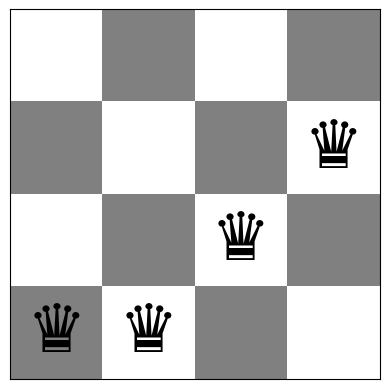

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [ ]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


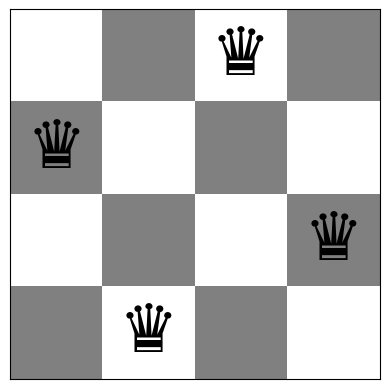

In [ ]:
board = [1,3,0,2]
show_board(board)

In [ ]:
n = 8
board = random_board(n)

print("Bàn cờ:", board)
print("Số cặp xung đột:", conflicts(board))

Bàn cờ: [4 4 0 1 7 1 7 1]
Số cặp xung đột: 8


In [ ]:
def get_neighbors(board):
    n = len(board)
    neighbors = []

    # Thử chuyển quân hậu ở từng cột sang các hàng khác
    for col in range(n):
        for row in range(n):
            if row != board[col]:
                new_board = board.copy()
                new_board[col] = row
                neighbors.append(new_board)

    return neighbors

In [ ]:
board = random_board(8)
neighbors = get_neighbors(board)

print("Bàn cờ ban đầu:", board)
print("Số trạng thái lân cận:", len(neighbors))
print("Một trạng thái lân cận:", neighbors[0])

Bàn cờ ban đầu: [2 6 3 6 4 4 2 6]
Số trạng thái lân cận: 56
Một trạng thái lân cận: [0 6 3 6 4 4 2 6]


# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

In [ ]:
# Code and description go here
import time
def steepest_ascent_hill_climbing(n, max_steps=1000):
    board = random_board(n)
    current_conflicts = conflicts(board)
    evaluations = 1  # Lần đánh giá bàn cờ ban đầu
    steps = 0
    history = [current_conflicts]
    start_time = time.time()

    while current_conflicts > 0 and steps < max_steps:
        neighbors = get_neighbors(board)
        best_board = board
        best_conflicts = current_conflicts

        # Đánh giá toàn bộ trạng thái lân cận
        for neighbor in neighbors:
            neighbor_conflicts = conflicts(neighbor)
            evaluations += 1
            if neighbor_conflicts < best_conflicts:
                best_board = neighbor
                best_conflicts = neighbor_conflicts
        # Không tìm được bước cải thiện thì dừng
        if best_conflicts >= current_conflicts:
            break

        board = best_board
        current_conflicts = best_conflicts
        steps += 1
        history.append(current_conflicts)

    runtime = time.time() - start_time

    return {
        "board": board,
        "conflicts": current_conflicts,
        "steps": steps,
        "evaluations": evaluations,
        "runtime": runtime,
        "history": history
    }

In [ ]:
# chay thu
result_steepest = steepest_ascent_hill_climbing(8)

print("Bàn cờ cuối:", result_steepest["board"])
print("Số xung đột:", result_steepest["conflicts"])
print("Số bước:", result_steepest["steps"])
print("Số lần đánh giá conflicts:", result_steepest["evaluations"])
print("Thời gian chạy:", result_steepest["runtime"])
print("Lịch sử xung đột:", result_steepest["history"])

Bàn cờ cuối: [2 0 6 1 5 0 3 7]
Số xung đột: 2
Số bước: 3
Số lần đánh giá conflicts: 225
Thời gian chạy: 0.0028977394104003906
Lịch sử xung đột: [7, 4, 3, 2]


In [ ]:
# Chạy lại thuật toán vài lần để xem có lần nào đạt 0 không. Vì bàn cờ khởi tạo ngẫu nhiên, mỗi lần chạy có thể cho kết quả khác nhau:
for i in range(10):
    result = steepest_ascent_hill_climbing(8)
    print(
        f"Lần {i+1}: conflicts={result['conflicts']}, "
        f"steps={result['steps']}, "
        f"evaluations={result['evaluations']}"
    )

Lần 1: conflicts=2, steps=2, evaluations=169
Lần 2: conflicts=1, steps=4, evaluations=281
Lần 3: conflicts=2, steps=3, evaluations=225
Lần 4: conflicts=1, steps=3, evaluations=225
Lần 5: conflicts=1, steps=2, evaluations=169
Lần 6: conflicts=1, steps=4, evaluations=281
Lần 7: conflicts=1, steps=4, evaluations=281
Lần 8: conflicts=1, steps=3, evaluations=225
Lần 9: conflicts=2, steps=3, evaluations=225
Lần 10: conflicts=2, steps=4, evaluations=281


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [ ]:
# Code and description go here
import random
def inefficient_stochastic_hill_climbing(n, max_steps=1000):
    board = random_board(n)
    current_conflicts = conflicts(board)
    evaluations = 1
    steps = 0
    history = [current_conflicts]
    start_time = time.time()

    while current_conflicts > 0 and steps < max_steps:
        neighbors = get_neighbors(board)
        improving_neighbors = []
        # Đánh giá toàn bộ lân cận và lọc ra các trạng thái tốt hơn
        for neighbor in neighbors:
            neighbor_conflicts = conflicts(neighbor)
            evaluations += 1
            if neighbor_conflicts < current_conflicts:
                improving_neighbors.append((neighbor, neighbor_conflicts))
        # Nếu không có trạng thái nào tốt hơn thì dừng
        if not improving_neighbors:
            break

        # Chọn ngẫu nhiên một trong số các nước đi giúp cải thiện
        best_board, best_conflicts = random.choice(improving_neighbors)
        board = best_board
        current_conflicts = best_conflicts
        steps += 1
        history.append(current_conflicts)

    runtime = time.time() - start_time

    return {
        "board": board,
        "conflicts": current_conflicts,
        "steps": steps,
        "evaluations": evaluations,
        "runtime": runtime,
        "history": history
    }

In [ ]:
# Thử nghiệm 10 lần với Inefficient Stochastic Hill Climbing
print("--- THỬ NGHIỆM INEFFICIENT STOCHASTIC ---")
for i in range(10):
    res = inefficient_stochastic_hill_climbing(8)
    print(f"Lần {i+1}: conflicts={res['conflicts']}, steps={res['steps']}, evaluations={res['evaluations']}")

--- THỬ NGHIỆM INEFFICIENT STOCHASTIC ---
Lần 1: conflicts=1, steps=7, evaluations=449
Lần 2: conflicts=1, steps=3, evaluations=225
Lần 3: conflicts=2, steps=7, evaluations=449
Lần 4: conflicts=1, steps=8, evaluations=505
Lần 5: conflicts=2, steps=5, evaluations=337
Lần 6: conflicts=1, steps=7, evaluations=449
Lần 7: conflicts=1, steps=4, evaluations=281
Lần 8: conflicts=2, steps=6, evaluations=393
Lần 9: conflicts=2, steps=4, evaluations=281
Lần 10: conflicts=1, steps=4, evaluations=281


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [ ]:
# Code and description go here
def efficient_stochastic_hill_climbing(n, max_steps=1000, max_tries=100):
    board = random_board(n)
    current_conflicts = conflicts(board)
    evaluations = 1
    steps = 0
    history = [current_conflicts]
    start_time = time.time()

    while current_conflicts > 0 and steps < max_steps:
        found_better = False
        # Thử chọn ngẫu nhiên một lân cận tối đa 'max_tries' lần
        for _ in range(max_tries):
            col = random.randint(0, n - 1)
            row = random.randint(0, n - 1)

            if row != board[col]:
                neighbor = board.copy()
                neighbor[col] = row
                neighbor_conflicts = conflicts(neighbor)
                evaluations += 1

                # Nếu tốt hơn thì lập tức chấp nhận
                if neighbor_conflicts < current_conflicts:
                    board = neighbor
                    current_conflicts = neighbor_conflicts
                    steps += 1
                    history.append(current_conflicts)
                    found_better = True
                    break
        # Nếu thử nhiều lần không tìm được trạng thái tốt hơn thì dừng
        if not found_better:
            break
    runtime = time.time() - start_time

    return {
        "board": board,
        "conflicts": current_conflicts,
        "steps": steps,
        "evaluations": evaluations,
        "runtime": runtime,
        "history": history
    }

In [ ]:
# Thử nghiệm 10 lần với Efficient Stochastic Hill Climbing
print("--- THỬ NGHIỆM EFFICIENT STOCHASTIC ---")
for i in range(10):
    res = efficient_stochastic_hill_climbing(8)
    print(f"Lần {i+1}: conflicts={res['conflicts']}, steps={res['steps']}, evaluations={res['evaluations']}")

--- THỬ NGHIỆM EFFICIENT STOCHASTIC ---
Lần 1: conflicts=2, steps=4, evaluations=180
Lần 2: conflicts=2, steps=6, evaluations=113
Lần 3: conflicts=1, steps=5, evaluations=152
Lần 4: conflicts=1, steps=5, evaluations=110
Lần 5: conflicts=2, steps=6, evaluations=136
Lần 6: conflicts=1, steps=5, evaluations=209
Lần 7: conflicts=2, steps=4, evaluations=154
Lần 8: conflicts=2, steps=4, evaluations=108
Lần 9: conflicts=3, steps=3, evaluations=121
Lần 10: conflicts=2, steps=4, evaluations=110


In [ ]:
def random_restart_hill_climbing(n, max_restarts=100, max_steps_per_run=1000):
    total_evaluations = 0
    total_steps = 0
    start_time = time.time()

    for restart in range(max_restarts):
        # Sử dụng Steepest-ascent làm thuật toán leo đồi cơ sở
        board = random_board(n)
        current_conflicts = conflicts(board)
        total_evaluations += 1
        steps = 0

        while current_conflicts > 0 and steps < max_steps_per_run:
            neighbors = get_neighbors(board)
            best_board = board
            best_conflicts = current_conflicts

            for neighbor in neighbors:
                neighbor_conflicts = conflicts(neighbor)
                total_evaluations += 1
                if neighbor_conflicts < best_conflicts:
                    best_board = neighbor
                    best_conflicts = neighbor_conflicts

            if best_conflicts >= current_conflicts:
                break

            board = best_board
            current_conflicts = best_conflicts
            steps += 1
            total_steps += 1

        # Nếu đạt trạng thái đích lý tưởng
        if current_conflicts == 0:
            runtime = time.time() - start_time
            return {
                "board": board,
                "conflicts": current_conflicts,
                "steps": total_steps,
                "evaluations": total_evaluations,
                "runtime": runtime,
                "restarts": restart
            }

    runtime = time.time() - start_time
    return {
        "board": board,
        "conflicts": current_conflicts,
        "steps": total_steps,
        "evaluations": total_evaluations,
        "runtime": runtime,
        "restarts": max_restarts - 1
    }

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [ ]:
# Code and description go here (k xoá dòng này)

import time
import pandas as pd

def random_restart(algorithm, n=8, max_restarts=100):
    start = time.perf_counter()
    best_board = None
    best_conflicts = float("inf")
    total_steps = 0
    restarts_used = 0

    for restart in range(1, max_restarts + 1):
        # Mỗi lần chạy phải bắt đầu từ một bàn cờ ngẫu nhiên mới.
        board = random_board(n)
        result = algorithm(board)

        # Điều chỉnh phần này nếu thuật toán trả về kiểu dữ liệu khác.
        if isinstance(result, tuple):
            final_board = result[0]
            steps = result[1] if len(result) > 1 else 0
        else:
            final_board = result
            steps = 0

        score = conflicts(final_board)
        total_steps += steps
        restarts_used = restart

        if score < best_conflicts:
            best_conflicts = score
            best_board = final_board.copy()

        if score == 0:
            break

    return {
        "Algorithm": algorithm.__name__,
        "N": n,
        "Best conflicts": best_conflicts,
        "Solution found": best_conflicts == 0,
        "Restarts used": restarts_used,
        "Total steps": total_steps,
        "Runtime (s)": round(time.perf_counter() - start, 5),
        "Board": best_board
    }

algorithms = [
    steepest_ascent_hill_climbing,
    inefficient_stochastic_hill_climbing,
    efficient_stochastic_hill_climbing
]

results = []
for algorithm in algorithms:
    results.append(random_restart(algorithm, n=8, max_restarts=100))

df_task4 = pd.DataFrame(results)
display(df_task4.drop(columns=["Board"]))



TypeError: only integer scalar arrays can be converted to a scalar index

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [ ]:
# Code and description go here (k xoá dòng này)

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [ ]:
# Code (k xoá dòng này)

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [ ]:
# Code and description go here (k xoá dòng này)

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [ ]:
# Code and description go here (k xoá dòng này)

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [ ]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem

In [ ]:
# Code and description go here